# 新能源车产业链：各环节是同步波动，还是依次传导？

2020-01-02 至 2026-11-20，31 只 A 股标的 + 沪深300 基准，1,668 个交易日，52,852 条日频观测。
数据是腾讯行情的前复权日线，采集脚本在 `scripts/fetch_prices.py`；这个 notebook 直接用它的落盘结果，
不联网也能重跑。

起因是这样：2020 到 2026 年，这条链走完了一轮完整周期——补贴驱动的高增长、锂价暴涨带来的上游暴利、
产能过剩与出清、2025 年三季度的集体反弹，再到 2026 年的回调。做供应链的人绕不开一个具体问题：
**链条上的环节到底是同步波动，还是上游先动、下游后动？**

如果能找到一个稳定的滞后，采购节奏和库存前置期就能按上游来排。如果找不到，那"跟着上游做下游"
这套逻辑本身就得重新想一想。

所以这件事要转成一个能证伪的命题：层级之间的交叉相关里，能不能找到一个**稳定的、非零的**最优滞后。

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

df = pd.read_csv("data/raw_panel.csv", parse_dates=["date"], dtype={"code": str})
df.shape

(52852, 11)

52,852 行 × 10 列。每行是「某只标的某天的 OHLC + 成交量」。
`layer` 字段是我自己按产业链位置打的标签，一共五层：

| 层级 | 数量 | 说明 |
|---|---|---|
| 上游资源 | 7 | 锂、钴、盐湖 |
| 中游材料 | 9 | 正极、负极、隔膜、电解液 |
| 中游电池 | 5 | 电芯与 PACK |
| 下游整车 | 8 | 乘用车与商用车 |
| 传统车对照 | 2 | 燃油车，用来对比"是不是整个汽车板块都在涨" |
| 基准 | 1 | 沪深300 |

31 只个股 + 1 个指数 = 32 个代码。

In [2]:
meta = df.drop_duplicates("code")[["code", "name", "layer"]]
print(meta.groupby("layer").size().to_string())
print()
print("交易日数：", df["date"].nunique())
print("区间：", df["date"].min().date(), "→", df["date"].max().date())
print("代码数：", df["code"].nunique())

layer
上游资源     7
下游整车     8
中游材料     9
中游电池     5
传统车对照    2
基准       1

交易日数： 1668
区间： 2020-01-02 → 2026-11-20
代码数： 32


## 先检查数据能不能用

最怕三件事：重复行、停牌造成的空洞、以及除权除息没处理干净。前两个能查，第三个只能信数据源
（腾讯的前复权口径在跨除权日时偶尔会有微小跳变，肉眼看不出来，这里没法验证）。

In [3]:
print("缺失值：", int(df.isna().sum().sum()))
print("date+code 重复：", int(df.duplicated(["date", "code"]).sum()))
print("零成交量：", int((df["volume"] == 0).sum()))

# 每个标的的交易日覆盖度
cover = (df.groupby(["code", "name"])["date"].count() / df["date"].nunique() * 100).sort_values()
cover.head(4).round(1)

缺失值： 0
date+code 重复： 0
零成交量： 0


code    name
000792  盐湖股份    81.3
688567  孚能科技    91.8
002812  恩捷股份    99.1
002176  江特电机    99.3
Name: date, dtype: float64

盐湖股份只有 81.3% 的覆盖率，因为 2019–2021 年一直在停牌；孚能科技 91.8%，2020 年 7 月才上市。
其余都在 99% 以上。

处理方式：**不插值**。等权合成层级收益时，当天没有数据的标的不参与均值（`mean(axis=1)` 会自动跳过 NaN），
这样既不会凭空造出一条直线，也不会把停牌标的的旧价格当成新信息。

然后是极值。个股口径的日收益要一只一只算，跨停牌会算出一个巨大的"单日"涨幅：

In [4]:
ret_ind = df.sort_values("date").groupby("code")["close"].pct_change()
ext = pd.DataFrame({"date": df["date"], "name": df["name"], "ret": ret_ind * 100}).dropna()
print("最大三日：")
print(ext.nlargest(3, "ret").to_string(index=False))
print("\n最小三日：")
print(ext.nsmallest(3, "ret").to_string(index=False))

最大三日：
      date name        ret
2021-08-10 盐湖股份 306.108597
2020-10-09 当升科技  21.171489
2021-09-07  新宙邦  20.875912

最小三日：
      date name        ret
2025-04-07  欣旺达 -20.310982
2025-04-07 寒锐钴业 -20.169731
2025-04-07 德方纳米 -19.993612


盐湖股份 2021-08-10 的 +306.11%，其实是它停牌 16 个月复牌当天的累计涨幅——
前一天的价格还停在 2020-04-29。这种记录不能当"一日收益"用，否则上游资源那一层的
当日均值会被它一个人抬走四十多个点，后面所有二阶矩指标全部失真。

所以处理分两层：

1. **层级收益**用透视后的日历做 `pct_change()`：停牌日在矩阵里是 NaN，`mean(axis=1)` 自动跳过，
   复牌当天的跳变不进入层级收益。这跟"等权合成时缺失标的不参与"是同一条原则。
2. **再按 0.1% / 99.9% 分位缩尾**。剩下的极值都挤在涨跌停附近，缩尾不动中位数和分位结构。

In [5]:
piv = df.pivot(index="date", columns="code", values="close").sort_index()
layer_of = meta.set_index("code")["layer"]
name_of = meta.set_index("code")["name"]
ret = piv.pct_change()

lr = pd.DataFrame({
    layer: ret[[c for c in layer_of[layer_of == layer].index if c in ret.columns]].mean(axis=1)
    for layer in layer_of.unique()
})
lr = lr.clip(lower=lr.quantile(0.001), upper=lr.quantile(0.999), axis=1)
lr = lr[["上游资源", "中游材料", "中游电池", "下游整车", "传统车对照", "基准"]]

idx = (1 + lr.fillna(0)).cumprod()
idx.head(3).round(4)

,上游资源,中游材料,中游电池,下游整车,传统车对照,基准
date,,,,,,
2020-01-02,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2020-01-03,1.0215,1.0018,0.9889,0.9950,1.0120,0.9982
2020-01-06,1.0705,1.0650,1.0339,0.9844,1.0017,0.9945


## 第一个问题：谁涨得多

把每层等权成一个净值曲线（2020-01-02 = 1），累乘得到下面的图。

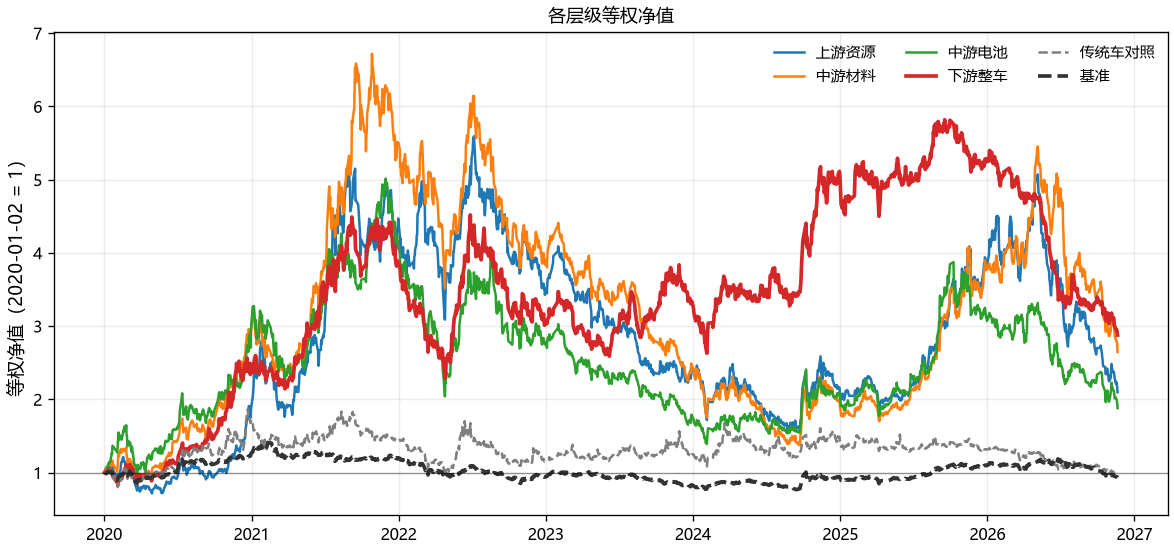

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.8))
colors = {"上游资源": "#1f77b4", "中游材料": "#ff7f0e", "中游电池": "#2ca02c",
          "下游整车": "#d62728", "传统车对照": "#7f7f7f", "基准": "#333333"}
for col in idx.columns:
    ax.plot(idx.index, idx[col], label=col, lw=2.2 if col in ("下游整车", "基准") else 1.5,
            color=colors[col], ls="--" if col in ("传统车对照", "基准") else "-")
ax.axhline(1, color="k", lw=0.8, alpha=0.4)
ax.set_ylabel("等权净值（2020-01-02 = 1）")
ax.set_title("各层级等权净值")
ax.legend(frameon=False, ncol=3, fontsize=9)
plt.tight_layout()
plt.savefig("charts/01_cumulative.png", bbox_inches="tight")
plt.show()

In [7]:
years = (idx.index[-1] - idx.index[0]).days / 365.25
stats = pd.DataFrame({
    "累计收益%": (idx.iloc[-1] - 1) * 100,
    "年化收益%": (idx.iloc[-1] ** (1 / years) - 1) * 100,
    "年化波动%": lr.std() * np.sqrt(252) * 100,
    "最大回撤%": (idx / idx.cummax() - 1).min() * 100,
    "当前历史分位%": (idx < idx.iloc[-1]).mean() * 100,
}).round(1)
stats

,累计收益%,年化收益%,年化波动%,最大回撤%,当前历史分位%
上游资源,109.8,11.4,44.8,-71.6,27.3
中游材料,164.8,15.2,42.5,-79.5,43.1
中游电池,88.1,9.6,43.2,-72.3,23.0
下游整车,187.7,16.6,34.1,-50.6,25.6
传统车对照,-6.9,-1.0,34.7,-50.2,1.6
基准,-6.5,-1.0,18.7,-45.6,30.9


六年十一个月，下游整车累计 **+187.7%**、中游材料 +164.8%、上游资源 +109.8%、中游电池 +88.1%，
而沪深300 是 −6.5%，传统车对照组 −6.9%。

四个环节全部大幅跑赢大盘，这点没什么争议。真正值得记的是两件事：

1. **环节之间拉开了近 100 个百分点**（整车 187.7 vs 电池 88.1）。
2. **收益最高的一层，风险反而最低**。整车年化波动 34.1%、最大回撤 −50.6%；
   中游材料波动 42.5%、回撤 −79.5%。买"整条链"和买"整车"根本不是一个风险敞口。

分年度看，轮动顺序更清楚：

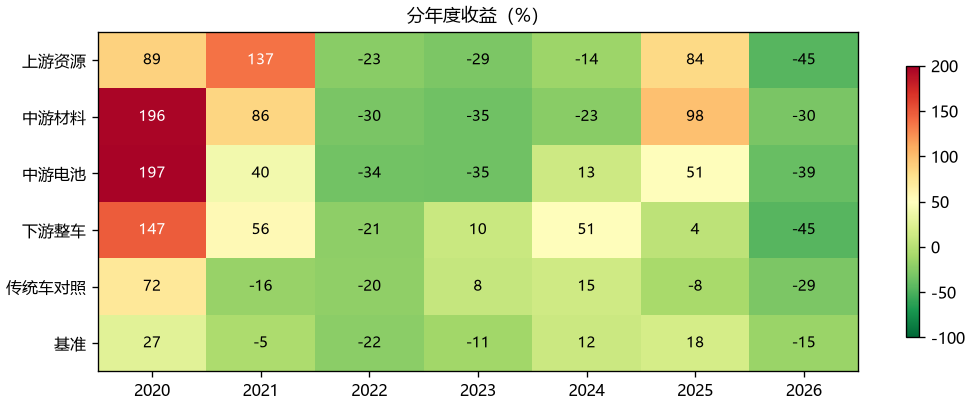

,上游资源,中游材料,中游电池,下游整车,传统车对照,基准
date,,,,,,
2020,88.6,195.6,197.4,147.4,71.5,26.6
2021,137.1,86.3,39.6,55.8,-16.2,-5.2
2022,-23.3,-30.3,-33.8,-21.4,-19.7,-21.6
2023,-29.0,-35.4,-34.8,10.4,8.0,-11.4
2024,-14.1,-23.2,13.1,51.4,14.6,11.6
2025,83.5,98.2,51.4,3.6,-8.0,17.7
2026,-45.4,-29.8,-38.7,-45.2,-29.2,-14.6


In [8]:
ye = idx.resample("YE").last()
prev = ye.shift(1)
prev.iloc[0] = 1.0                      # 首年从 2020-01-02 的起点算
year_ret = ((ye / prev - 1) * 100).round(1)
year_ret.index = year_ret.index.year

fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(year_ret.T.values, cmap="RdYlGn_r", aspect="auto", vmin=-100, vmax=200)
ax.set_xticks(range(len(year_ret)), year_ret.index)
ax.set_yticks(range(len(year_ret.columns)), year_ret.columns)
for i in range(len(year_ret.columns)):
    for j in range(len(year_ret)):
        v = year_ret.iloc[j, i]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 110 else "black")
ax.set_title("分年度收益（%）")
ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.savefig("charts/02_yearly_heatmap.png", bbox_inches="tight")
plt.show()
year_ret

2020 年中游材料和电池领涨（196%、197%），2021 年利润往最上游集中（上游 +137%，电池只剩 +40%），
2022–23 全链条连跌两年，2025 年三季度单季 +56% 到 +66% 集体冲高，2026 年又全部吐回去。

到这一步还只是"谁涨得多"。真正的问题在后面。

## 第二个问题：有没有传导时滞

做法是交叉相关。对每一对层级（上游→电池、电池→整车、上游→整车、材料→整车），
在 lag = −60 到 +60 期之间扫一遍，看绝对相关系数最大落在哪一期。
日、周、月三个频段各做一次——日频看交易情绪，月频看基本面，如果只有日频是 0，
说明可能只是同步交易，那月频应该能露出来。

lag > 0 表示左项领先右项。

In [9]:
ORDER = ["上游资源", "中游材料", "中游电池", "下游整车"]

def resample_ret(freq):
    px = (1 + lr.fillna(0)).cumprod()
    return px.resample(freq).last().pct_change().dropna()

def best_lag(a, b, max_lag):
    s = pd.Series({lag: a.corr(b.shift(lag)) for lag in range(-max_lag, max_lag + 1)})
    return s.abs().idxmax(), s.max(), s.iloc[len(s) // 2]

pairs = [("上游资源", "中游电池"), ("中游电池", "下游整车"),
         ("上游资源", "下游整车"), ("中游材料", "下游整车")]
rows = []
for freq, maxlag, label in [("D", 20, "日频"), ("W", 12, "周频"), ("ME", 6, "月频")]:
    r = lr if freq == "D" else resample_ret(freq)
    for a, b in pairs:
        lag, val, r0 = best_lag(r[a], r[b], maxlag)
        rows.append({"路径": f"{a} → {b}", "频段": label, "样本": len(r),
                     "最优lag": lag, "最优r": round(val, 3), "同期r": round(r0, 3)})
lag_tab = pd.DataFrame(rows)
lag_tab.pivot(index="路径", columns="频段", values="最优lag")[["日频", "周频", "月频"]]

频段,日频,周频,月频
路径,,,
上游资源 → 下游整车,0,0,0
上游资源 → 中游电池,0,0,0
中游材料 → 下游整车,0,0,0
中游电池 → 下游整车,0,0,0


In [10]:
lag_tab.pivot(index="路径", columns="频段", values="同期r")[["日频", "周频", "月频"]]

频段,日频,周频,月频
路径,,,
上游资源 → 下游整车,0.551,0.530,0.536
上游资源 → 中游电池,0.694,0.658,0.702
中游材料 → 下游整车,0.557,0.528,0.549
中游电池 → 下游整车,0.615,0.608,0.640


十二个格子，最优滞后**全是 0**。不是 1 天，不是 1 周，是同期。

同期相关随链条距离单调衰减：上游→电池 0.694，电池→整车 0.615，上游→整车 0.551，
材料→整车 0.557。这个梯度说明结构关系本身是真实存在的——离得越远，联动越弱。
但**滞后项一点增量信息都没有**。

我的解释是：真实的传导发生在基本面（锂价 → 正极成本 → 电池报价 → 整车毛利），
而二级市场是对同一批公开信息同时定价的，传导过程被预期提前吃掉了。
这个解释对不对我没法在这份数据里验证——要验证得用现货价格和排产数据，见文末"下一步"。

但结论本身是稳的：**任何基于"上游先涨、下游后涨"的轮动策略，在 2020–2026 这段样本里没有统计支撑。**

顺手看一眼层级之间的日收益相关矩阵，算是给上面的结论做个旁证。

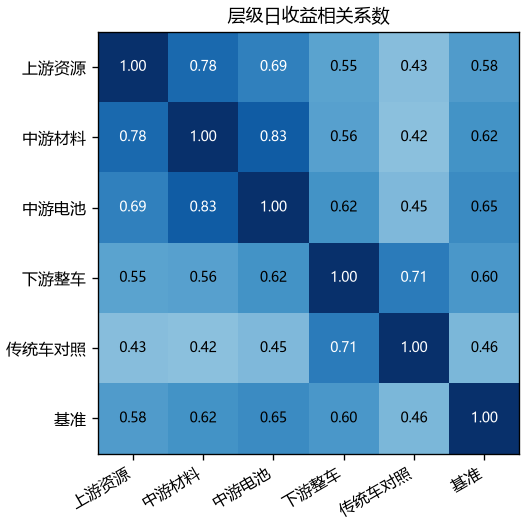

,上游资源,中游材料,中游电池,下游整车,传统车对照,基准
上游资源,1.00,0.78,0.69,0.55,0.43,0.58
中游材料,0.78,1.00,0.83,0.56,0.42,0.62
中游电池,0.69,0.83,1.00,0.62,0.45,0.65
下游整车,0.55,0.56,0.62,1.00,0.71,0.60
传统车对照,0.43,0.42,0.45,0.71,1.00,0.46
基准,0.58,0.62,0.65,0.60,0.46,1.00


In [11]:
cm = lr.corr().round(2)
fig, ax = plt.subplots(figsize=(6, 4.6))
im = ax.imshow(cm.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(cm)), cm.columns, rotation=30, ha="right")
ax.set_yticks(range(len(cm)), cm.index)
for i in range(len(cm)):
    for j in range(len(cm)):
        ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if cm.iloc[i, j] > 0.65 else "black")
ax.grid(False)
ax.set_title("层级日收益相关系数")
plt.tight_layout()
plt.savefig("charts/06_corr_matrix.png", bbox_inches="tight")
plt.show()
cm

中游材料和电池最高（0.83），上游和材料 0.78；传统车跟新能源各层只有 0.42–0.45，
说明"新能源"确实是一条独立的链，不是整个汽车板块在齐涨齐跌。

## 第三个问题：联动强度是稳定的吗

上面那张表算的是全样本平均。如果联动本身在变化，平均就会掩盖掉结构性的松动。
所以再看 60 日滚动相关。

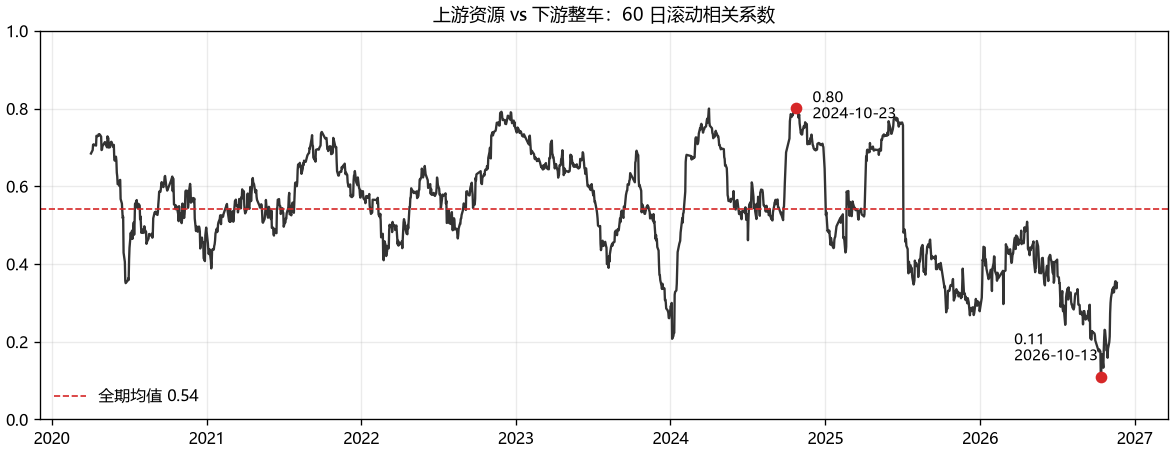

均值 0.542 | 当前 0.351 | 最高 0.801 (2024-10-23) | 最低 0.109 (2026-10-13)


In [12]:
roll = lr["上游资源"].rolling(60).corr(lr["下游整车"]).dropna()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(roll.index, roll, color="#333333", lw=1.4)
ax.axhline(roll.mean(), color="#d62728", ls="--", lw=1, label=f"全期均值 {roll.mean():.2f}")
peak, trough = roll.idxmax(), roll.idxmin()
ax.scatter([peak, trough], [roll.max(), roll.min()], color="#d62728", zorder=5)
ax.annotate(f"{roll.max():.2f}\n{peak.date()}", (peak, roll.max()), xytext=(10, -6),
            textcoords="offset points", fontsize=9)
ax.annotate(f"{roll.min():.2f}\n{trough.date()}", (trough, roll.min()), xytext=(-52, 10),
            textcoords="offset points", fontsize=9)
ax.set_ylim(0, 1)
ax.set_title("上游资源 vs 下游整车：60 日滚动相关系数")
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.savefig("charts/03_rolling_corr.png", bbox_inches="tight")
plt.show()

print(f"均值 {roll.mean():.3f} | 当前 {roll.iloc[-1]:.3f} | 最高 {roll.max():.3f} ({peak.date()}) | 最低 {roll.min():.3f} ({trough.date()})")

In [13]:
print((roll.resample("QE").mean().dropna().tail(8) * 1).round(2).to_string())

date
2025-03-31    0.51
2025-06-30    0.72
2025-09-30    0.43
2025-12-31    0.31
2026-03-31    0.40
2026-06-30    0.42
2026-09-30    0.29
2026-12-31    0.24
Freq: QE-DEC


2024 年 10 月 23 日摸到 0.801，之后一路往下，2026 年 10 月 13 日跌到 0.109，最新值 0.351。

按季度看是阶梯式往下走：2025Q2 还有 0.72，2025Q4 掉到 0.31，2026Q3 是 0.29，
2026Q4 只剩 0.24（只统计到 11-20，样本不满一个季度）。

这条线的含义比收益曲线更值得盯：**"买新能源车产业链"作为一个整体交易策略，内部一致性已经大幅削弱。**
当 beta 的联动性下降，研究颗粒度就必须下沉到环节乃至单家公司。对供应链管理来说，
意味着不能再用"行业景气"一个指标统一安排各环节的采购与库存——
上游和中下游已经进入不同的景气节奏。

## 第四个问题：利润在链条上怎么分

用上游净值除以整车净值，得到一条粗略的利润分配代理曲线。比值上升代表利润往上游集中。

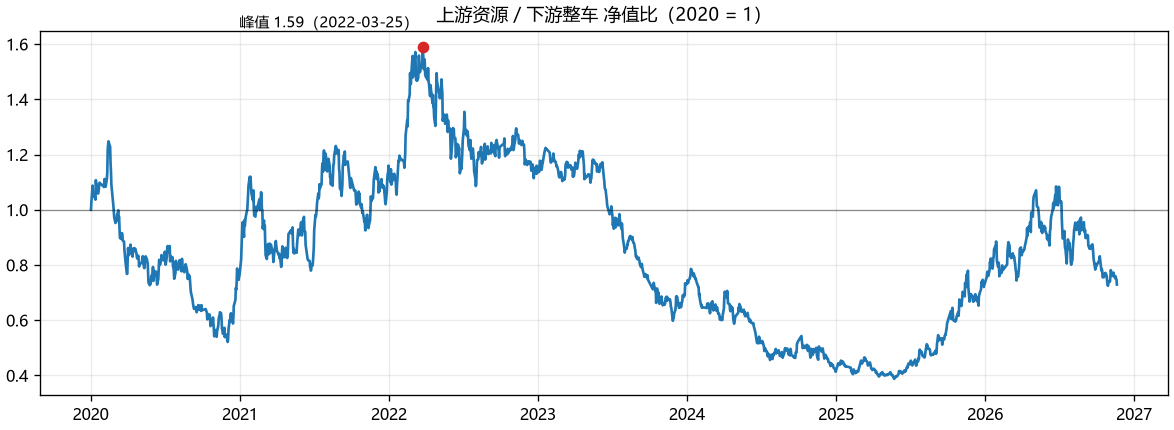

峰值 1.588 @ 2022-03-25 | 当前 0.729 | 较峰值 -54.1%


In [14]:
ratio = idx["上游资源"] / idx["下游整车"]
ratio_n = ratio / ratio.iloc[0]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(ratio_n.index, ratio_n, color="#1f77b4", lw=1.6)
ax.axhline(1, color="k", lw=0.8, alpha=.4)
p = ratio_n.idxmax()
ax.scatter([p], [ratio_n.max()], color="#d62728", zorder=5)
ax.annotate(f"峰值 {ratio_n.max():.2f}（{p.date()}）", (p, ratio_n.max()),
            xytext=(-110, 12), textcoords="offset points", fontsize=9)
ax.set_title("上游资源 / 下游整车 净值比（2020 = 1）")
plt.tight_layout()
plt.savefig("charts/04_profit_shift.png", bbox_inches="tight")
plt.show()

print(f"峰值 {ratio_n.max():.3f} @ {p.date()} | 当前 {ratio_n.iloc[-1]:.3f} | 较峰值 {(ratio_n.iloc[-1]/ratio_n.max()-1)*100:.1f}%")

2022 年 3 月 25 日见顶 1.588——那是锂价最疯的时候——之后一路回落到 0.729，
比峰值低 54%，已经跌回 2020 年的起点附近。

也就是说 2021–22 年上游攫取超额利润的阶段结束了。2025 年上游有过一波反弹（年度 +84%），
但没改变比价曲线的下行方向。

对采购谈判的含义很直接：长协价格和账期谈判的筹码正在往中下游转移。

## 最后一个问题：单个标的

层级指数会把个股的极端情况平滑掉。回到单只标的，看波动率和收益到底是不是正相关——
按理说承担更高波动应该换来更高收益。

In [15]:
# 个股波动率按 A 股 ±20% 的涨跌停口径缩尾，否则一两个涨停日就能把年化波动抬到不合理的水平
perf = []
for c in piv.columns:
    s = piv[c].dropna()
    r = s.pct_change().dropna().clip(-0.2, 0.2)
    perf.append({"名称": name_of.get(c, c), "层级": layer_of.get(c, ""),
                 "累计收益%": (s.iloc[-1] / s.iloc[0] - 1) * 100,
                 "年化波动%": r.std() * np.sqrt(252) * 100,
                 "最大回撤%": (s / s.cummax() - 1).min() * 100})
perf = pd.DataFrame(perf).sort_values("累计收益%", ascending=False)
perf.round(1).head(6)

,名称,层级,累计收益%,年化波动%,最大回撤%
10,比亚迪,下游整车,519.6,45.1,-53.8
19,宁德时代,中游电池,505.3,52.0,-66.5
12,中矿资源,上游资源,461.0,61.7,-66.9
11,天赐材料,中游材料,437.5,59.7,-84.6
25,赛力斯,下游整车,340.6,66.9,-76.6
23,江淮汽车,下游整车,245.8,59.2,-70.4


In [16]:
perf.round(1).tail(6)

,名称,层级,累计收益%,年化波动%,最大回撤%
17,欣旺达,中游电池,-18.9,54.7,-79.1
3,一汽解放,传统车对照,-40.6,34.3,-62.3
22,上汽集团,下游整车,-51.3,33.6,-63.7
26,广汽集团,下游整车,-57.2,38.7,-76.3
31,孚能科技,中游电池,-70.3,51.3,-83.4
18,寒锐钴业,上游资源,-74.7,53.1,-84.6


In [17]:
perf.sort_values("最大回撤%").round(1).head(5)

,名称,层级,累计收益%,年化波动%,最大回撤%
13,恩捷股份,中游材料,-12.6,52.2,-92.2
20,德方纳米,中游材料,34.9,65.5,-91.4
24,杉杉股份,中游材料,13.2,50.3,-85.4
29,璞泰来,中游材料,-7.5,50.8,-84.7
11,天赐材料,中游材料,437.5,59.7,-84.6


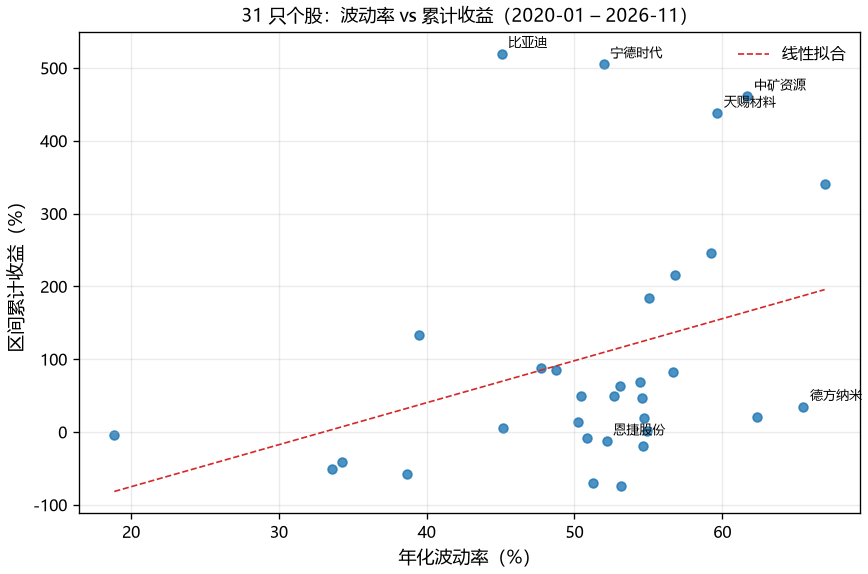

相关系数 r = +0.330  R² = 0.109


In [18]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(perf["年化波动%"], perf["累计收益%"], s=28, alpha=.8)
b, a = np.polyfit(perf["年化波动%"], perf["累计收益%"], 1)
xs = np.linspace(perf["年化波动%"].min(), perf["年化波动%"].max(), 20)
ax.plot(xs, a + b * xs, color="#d62728", ls="--", lw=1, label=f"线性拟合")
for _, row in perf.iterrows():
    if row["累计收益%"] > 400 or row["最大回撤%"] < -90:
        ax.annotate(row["名称"], (row["年化波动%"], row["累计收益%"]), fontsize=8,
                    xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("年化波动率（%）")
ax.set_ylabel("区间累计收益（%）")
ax.set_title("31 只个股：波动率 vs 累计收益（2020-01 – 2026-11）")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("charts/05_risk_scatter.png", bbox_inches="tight")
plt.show()

r = perf["年化波动%"].corr(perf["累计收益%"])
print(f"相关系数 r = {r:+.3f}  R² = {r**2:.3f}")

相关系数只有 **+0.33**，R² 不到 0.11。在这条链上，**承担更高波动并没有换来成比例的风险补偿**。

个股层面最惨的几个全在中游材料：恩捷股份最大回撤 −92.2%，德方纳米 −91.4%，杉杉股份 −85.4%。
而收益最高的三只——比亚迪 +520%、宁德时代 +505%、中矿资源 +461%——
回撤是 −53.8% / −66.5% / −66.9%，远好于中游材料动辄 −85% 的水平。

反过来看收益垫底的：寒锐钴业 −74.7%、孚能科技 −70.3%，回撤却深达 −84.6% 和 −83.4%。
既没赚到钱，波动也没少承担。

## 结论

1. **传导时滞不存在。** 日、周、月三个频段，四条路径，最优滞后全为 0；同期相关随链条距离单调衰减
   （0.69 → 0.62 → 0.55），说明结构关系真实，但滞后项没有增量信息。
2. **联动正在瓦解。** 上下游 60 日滚动相关从 2024-10 的 0.801 掉到 2026-10 的 0.109。
   层级 beta 的内部一致性在削弱，"买整条链"越来越不等于"买一个行业"。
3. **利润已经从上游迁回。** 上游/下游净值比自 2022-03 的峰值回落 54%。
4. **高波动没有换来高收益。** 31 只标的的波动率与累计收益相关仅 +0.33。

对供应链决策的直接含义：

- 不能再按 2021–22 年的紧缺逻辑给上游配库存，上游和中下游已经是两套景气节奏
- 中游材料是波动和回撤的双重震中，该环节的产能与库存决策需要更高的安全边际
- 上游议价力回落 54%，长协与账期的谈判筹码在中下游手上

## 局限

- **用股价代理景气度**，反映的是市场预期而不是产业基本面。这是这个分析最大的问题，
  也是下一步要替换的部分。
- **31 只标的是主动筛选的**，不是全样本，有幸存者偏差。
- **等权合成**，没按市值加权，小市值标的对层级指数的影响被放大。
- **没剥离外生冲击**：补贴退坡、购置税、疫情，都没有单独处理。

## 下一步

换成碳酸锂现货价、正极材料报价、月度排产和装机量，直接看产业基本面的传导时滞。
那才是供应链决策真正需要的信号；股价只能回答"市场怎么想"。

In [19]:
json.dump({
    "layer_stats": {k: {"cum": round(v["累计收益%"], 1), "cagr": round(v["年化收益%"], 1),
                        "vol": round(v["年化波动%"], 1), "mdd": round(v["最大回撤%"], 1)}
                    for k, v in stats.iterrows()},
    "current": {k: round(v, 1) for k, v in stats["当前历史分位%"].items()},
    "rolling_corr": {"mean": round(roll.mean(), 3), "last": round(roll.iloc[-1], 3),
                     "max": round(roll.max(), 3), "max_date": str(peak.date()),
                     "min": round(roll.min(), 3), "min_date": str(trough.date())},
    "ratio": {"peak": round(ratio_n.max(), 3), "peak_date": str(p.date()),
              "last": round(ratio_n.iloc[-1], 3)},
    "vol_ret_corr": round(r, 3),
    "stock_top": perf.head(5)[["名称", "层级", "累计收益%"]].round(1).to_dict("records"),
    "stock_worst": perf.tail(3)[["名称", "层级", "累计收益%"]].round(1).to_dict("records"),
}, open("data/metrics.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print("metrics.json written")

metrics.json written
